# Reading a coding ban inside Qwen3-8B — demo

**Question.** When a coding prompt *forbids* the algorithm a model would normally write, does the model invent
something new, or does it just swap in the next most common algorithm? And can a simple readout of the model's
internal state tell the two outcomes apart? This artifact asks both questions of **Qwen3-8B**, using two path-search
tasks from the iteration-1 suite:

| Task | The prompt asks for | Banned (modal) algorithm X | Main substitute X' |
|---|---|---|---|
| T1 grid path | `solve(grid, start, goal)` on a grid of strings | BFS | DFS |
| T2 weighted shortest path | a shortest path on a weighted graph | Dijkstra | Bellman-Ford / SPFA |

Every prompt carries one of five frozen ban templates, W1–W5. Two examples are *"Do not use {X} for this task."* and
*"{X} is not allowed here."*

**The full pipeline.** `method.py` is an orchestrator over `src/` with ten stages:
- vLLM generation on the FP8 twin: a fresh ban pool, a same-seed temperature sweep, thinking traces, and
  thought-anchor resampling.
- A canonical labeller: hidden tests, a runtime tracer and AST rules, with an LLM judge used only when they disagree.
- Hugging Face passes on the bf16 model: residual states, attention, an SAE transfer test, and J-lens.
- CPU readouts, and an independent re-derivation of the headline numbers.

The GPU stages need a 16 GB GPU, vLLM and about one GPU-hour, so **they are not run here**.

**What this notebook runs.** The steps below use the CPU only and take a few seconds. They run on 100 of the 200 runs
in the fresh ban pool (`fresh_ban_pool_protocol_v2`):
1. `final.fresh_pool_summary()`. How often does the model still write the banned algorithm? Reported per task and
   template, with Wilson CIs and the event gate.
2. The scoring half of `analysis.readout_i_replication()`. Readout objects were fitted on exp3 states:
   - the SAE readouts: the top-1 SAE latent, a logistic probe on the top-20 SAE latents, and DiM on the SAE code;
   - the baselines: DiM on the raw residual, a raw logistic probe, and the top-1 / top-20 raw dimensions.

   Each object was applied to every run's layer-27 residual state at `k_pre`, the token just before the model first
   writes an algorithm-identifying word. This step turns the stored per-run scores into pooled and within-template
   AUCs with run-bootstrap CIs.
3. Checks 1 and 5 of `verify_headlines.py`: an independent pandas / scikit-learn re-derivation and a shuffled-label
   placebo.

**Headline results of the full artifact** (for context):
- The banned share is 0.15 on T1 and 0.13 on T2. On T1 nearly all of it comes from one template: W4,
  *"BFS is not allowed here."*, gives 15/20 BFS, and the other templates give 0/20.
- The Qwen-Scope SAE fails its base→instruct transfer test at L15, L20 and L27. The dCE ratios are 3.29, 1.95 and
  1.59, all above the 1.5 limit, so every latent result is flagged out-of-distribution.
- On the fresh pool the exp3-fitted **DiM baseline transfers best**. Its within-template AUC at L27 is 1.00 on T1 and
  0.76 on T2. The single top SAE latent does not transfer (0.52 on T1, 0.51 on T2), and shuffled labels give about 0.50.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (version pinned in the artifact's pyproject.toml)
_pip('loguru==0.7.3')

# numpy, pandas, scipy, scikit-learn, matplotlib — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

import os

# The cgroup quota is ~5 CPUs while os.cpu_count() reports 48 host cores: cap every BLAS / OpenMP pool
# BEFORE numpy/torch load, or the oversubscribed thread pools are throttled ~100x.
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ.setdefault(_v, "4")
# notebook: method.py also sets CC=tools/zigcc (a C-compiler shim only vLLM's Triton needs), parses --stage with
# argparse and puts src/ on sys.path; none of that is needed here because the src/ code used below is copied inline.

import json  # core.py, final.py, verify_headlines.py
import math  # core.py
import sys
import time  # core.py
from collections import Counter, defaultdict  # final.py, analysis.py
from datetime import datetime, timezone  # core.py
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd  # verify_headlines.py
from loguru import logger
from scipy.stats import rankdata  # readout_i.py
from sklearn.metrics import roc_auc_score  # verify_headlines.py

import matplotlib.pyplot as plt  # notebook: inline figures (figures.py uses the Agg backend and savefig)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-2/experiment-12/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
EXAMPLES = data["datasets"][0]["examples"]
print(f'{data["datasets"][0]["dataset"]}: {len(EXAMPLES)} runs in the demo file')
print("selection:", data["metadata"]["selection"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
fresh_ban_pool_protocol_v2: 100 runs in the demo file
selection: 10 of 20 runs per task x template cell; proportional per label (largest remainder, >= 1 per label present, ties to the minority class); evenly spaced seeds; one T1 W2 run without a k_pre state kept; classes alternate inside a cell (minority first), runs the readout cannot use last. metadata_code = the generated program (results/labelled_c1.jsonl).


## Configuration

These are all the tunable parameters. The analysis is cheap, so the original values fit easily in the time budget.
`N_PER_CELL` takes the first *n* runs of every task × template cell. The demo file orders each cell so the two
outcome classes alternate, so even a small `N_PER_CELL` keeps both classes wherever a cell has both.

In [5]:
# ---- tunable parameters ------------------------------------------------------------------------------------------
N_PER_CELL = 10       # runs used per task x template cell (10 = the whole demo file; the original pool has 20)
N_BOOT = 2000         # bootstrap resamples over runs for the AUC CIs (= the original, analysis.py N_BOOT = 2000)
N_PLACEBO = 200       # shuffled-label placebo AUCs per config (= the original, verify_headlines.py)
C1_PER_TEMPLATE = 20  # runs per task x template in the original C1 pool (method.py default C1_PER_TEMPLATE=20)
# scaling log (clean local venv, notebook runtime incl. package install):
#   N_PER_CELL=2,  N_BOOT=1,    N_PLACEBO=1   -> 17 s
#   N_PER_CELL=5,  N_BOOT=200,  N_PLACEBO=20  -> 16 s
#   N_PER_CELL=10, N_BOOT=2000, N_PLACEBO=200 -> 24 s (original analysis values; ~9 s once packages are installed)

## 1. Protocol constants and IO helpers (`src/core.py`)

Every stage of `method.py` imports `core.py`, so the protocol constants live in one place. They are:
- the models: generation used the FP8 twin, while states, attention and CE used the bf16 weights;
- the label maps: banned X and substitute X' per task;
- the five frozen protocol-v2 templates, each with ban, mention and neutral twins;
- the seed conventions and the Wilson interval.

The code below is copied verbatim. Only the paths change: `ROOT` is the notebook's working directory instead of
`Path(__file__).parent.parent`. The iteration-1 input paths, the deviation log and the OpenRouter spend tracker are
left out because nothing here uses them.

In [6]:
ROOT = Path.cwd()  # notebook: replaces Path(__file__).resolve().parent.parent
RESULTS = ROOT / "results"
FIGS = ROOT / "figures"
LOGS = ROOT / "logs"
for _d in (RESULTS, FIGS, LOGS):
    _d.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- models (see deviations.json D01)
MODEL_HF = "Qwen/Qwen3-8B"            # bf16 weights: every state / attention / CE readout
MODEL_GEN = "Qwen/Qwen3-8B-FP8"       # official block-FP8 checkpoint: every vLLM generation (16 GB GPU)
MODEL_BASE = "Qwen/Qwen3-8B-Base"     # SAE training model, for the transfer test
SAE_REPO = "Qwen/SAE-Res-Qwen3-8B-Base-W64K-L0_50"
SAE_K = 50

TASKS = ("t1", "t2")
BANNED = {"t1": "bfs", "t2": "dijkstra"}           # X: the modal approach that the ban names
SUBSTITUTE = {"t1": "dfs", "t2": "bf_spfa"}        # X': the main natural substitute under the ban
X_NAME = {"t1": "breadth-first search (BFS)", "t2": "Dijkstra" + chr(39) + "s algorithm"}
XSUB_NAME = {"t1": "depth-first search (DFS)", "t2": "Bellman-Ford or SPFA"}

# Frozen protocol-v2 templates: (ban, mention, neutral)
TEMPLATES: dict[str, tuple[str, str, str]] = {
    "W1": ("Do not use {X} for this task.", "You could use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution may rely on {X}.",
           "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Consider {X} first.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{X} is allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that may use {X}.",
           "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)

# ---------------------------------------------------------------- seeds (plan CONVENTIONS)
SEED_FRESH = 20261020        # fresh pool: 20261020 + i
MAIN_DECODING = dict(temperature=1.0, top_p=1.0, top_k=-1)      # protocol thinking-off decoding


def setup_logging(name: str) -> None:
    """loguru: stdout INFO + rotating DEBUG file sink per stage."""
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, Path):
        return str(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _clean_nan(o: Any) -> Any:
    if isinstance(o, float) and not math.isfinite(o):
        return None
    if isinstance(o, dict):
        return {k: _clean_nan(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_clean_nan(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_clean_nan(json.loads(json.dumps(obj, default=_json_default))), indent=indent,
                              ensure_ascii=False))
    tmp.replace(p)


def read_json(p: Path, default: Any = None) -> Any:
    p = Path(p)
    if not p.exists():
        return default
    return json.loads(p.read_text())


def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float | None, float | None]:
    if n <= 0:
        return (None, None)
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


# ---------------------------------------------------------------- timing
TIMING = RESULTS / "timing.json"


def log_timing(stage: str, seconds: float, gpu: bool, **extra: Any) -> None:
    t = read_json(TIMING, {"stages": {}})
    rec = t["stages"].get(stage, {"runs": []})
    rec["runs"].append({"seconds": round(seconds, 1), "gpu": gpu, "utc": utc_now(), **extra})
    rec["total_seconds"] = round(sum(r["seconds"] for r in rec["runs"]), 1)
    t["stages"][stage] = rec
    t["gpu_hours_total"] = round(sum(sum(r["seconds"] for r in v["runs"] if r["gpu"])
                                     for v in t["stages"].values()) / 3600.0, 3)
    write_json(TIMING, t)


class Timer:
    def __init__(self, stage: str, gpu: bool, **extra: Any):
        self.stage, self.gpu, self.extra = stage, gpu, extra

    def __enter__(self) -> "Timer":
        self.t0 = time.time()
        logger.info(f"[{self.stage}] start")
        return self

    def __exit__(self, *exc: Any) -> None:
        dt = time.time() - self.t0
        log_timing(self.stage, dt, self.gpu, ok=exc[0] is None, **self.extra)
        logger.info(f"[{self.stage}] done in {dt / 60:.1f} min")


setup_logging("stage_demo")  # method.py: setup_logging(f"stage_{args.stage}") once per stage process

## 2. The orchestrator (`method.py`) and the rows this notebook rebuilds

In the original repository every stage runs as its own process (`uv run method.py --stage X`), because vLLM and the
Hugging Face model never share the 16 GB GPU:

| Stage | What it does | Hardware | In this notebook |
|---|---|---|---|
| `A` | inputs check, labeller re-check, prompt builder (W1–W5 ban / mention / neutral twins) | CPU | the prompts come with the data |
| `B` | layer probe and readout (i) discovery on exp3 states; fits the readout objects | CPU, 800 MB of states | not run (the objects are already applied) |
| `vllm1` | **C1 fresh ban pool** (2 tasks × 5 templates × 20 seeds, T = 1.0, thinking off) and the same-seed CRN sweep | GPU (vLLM) | not run (the generations come with the data) |
| `vllm2` | thought-anchor traces, resampling, completions | GPU (vLLM) | not run |
| `label` | canonical labeller on every generation; commit locator (defines `k_pre`) | CPU (+ LLM judge) | the labels come with the data |
| `hf` | E2 states and attention under the twins, SAE transfer test, J-lens | GPU (HF) | not run (the per-run scores come with the data) |
| `analyse` | readouts (i) replication, (ii) attention, (iii) prime-veto, thought anchors | CPU | **(i) replication scoring, section 5** |
| `final` | labeller check, **fresh-pool summary**, same-seed analysis, `method_out.json` | CPU | **fresh-pool summary, section 3** |
| `figures`, `verify` | figures; independent re-derivation and placebo checks | CPU | **verify checks 1 and 5, section 6** |

The CPU stages read two inputs. The first is `results/labelled_c1.jsonl`, with one labelled generation per row. The
second is the per-run readout scores that `readout_i_replication()` stored after it applied the exp3-fitted objects to
the E2 states. `final.method_out()` flattened both into the `exp_gen_sol_out` examples of `mini_demo_data.json` with
`ex_c1()`. Here is an excerpt:

```python
def ex_c1(r):
    pr = preds.get((r["task"], r["template"], r["sample_id"]), {})
    return {"input": P[r["prompt_key"]]["text"], "output": str(r["label"]), "metadata_task": r["task"],
            "metadata_template": r["template"], "metadata_seed": r["seed"], ...,
            "metadata_readout_layer": L1, "metadata_readout_scores_k_pre": pr, ...}
```

The next cell inverts that mapping so the original functions run unchanged. Three names stand in for the original
inputs:
- `C1_ROWS` for `labelled_c1.jsonl`;
- `SCORES` for `_readout_predictions()`;
- `E2_META` for `results/e2_meta.json`.

C1 run *i* has seed `20261020 + i`, counting over task → template → sample. So `sample_id = (seed − 20261020) mod 20`.

In [7]:
UNRES = {"no_code", "unresolved", None}
METHODS = ["sae_top1", "sae_top20_lr", "raw_dim", "raw_lr", "neuron_top1", "neuron_top20_lr", "sae_code_dim"]  # readout_i.py

# the first N_PER_CELL runs of every task x template cell (the demo file alternates the classes inside a cell)
_seen: Counter = Counter()
DEMO = []
for e in EXAMPLES:
    _c = (e["metadata_task"], e["metadata_template"])
    if _seen[_c] < N_PER_CELL:
        DEMO.append(e)
        _seen[_c] += 1


def c1_row(e: dict[str, Any]) -> dict[str, Any]:
    """Inverse of final.py's ex_c1(): one method_out example -> one results/labelled_c1.jsonl row."""
    t, w = e["metadata_task"], e["metadata_template"]
    return {"task": t, "template": w, "condition": "ban",
            "sample_id": (e["metadata_seed"] - SEED_FRESH) % C1_PER_TEMPLATE, "seed": e["metadata_seed"],
            "prompt_key": f"{t}|ban|{w}", "model": e["metadata_model"], "decoding": e["metadata_decoding"],
            "n_gen_tokens": e["metadata_n_gen_tokens"], "code": e.get("metadata_code"),
            "code_sha256": e["metadata_code_sha256"], "passed": e["metadata_passed"], "label": e["output"],
            "labeller_source": e["metadata_labeller_source"], "commit_idx": e["metadata_commit_idx"],
            "evidence_term": e["metadata_evidence_term"], "negated_first_mention": e["metadata_negated_first_mention"]}


C1_ROWS = [c1_row(e) for e in DEMO]                                     # stands in for results/labelled_c1.jsonl
PROMPTS = {r["prompt_key"]: e["input"] for r, e in zip(C1_ROWS, DEMO)}   # stands in for prompts/prompts_v2.json
SCORES = {(r["task"], r["template"], r["sample_id"]): e["metadata_readout_scores_k_pre"]
          for r, e in zip(C1_ROWS, DEMO)}                                # stands in for final._readout_predictions()
READOUT_LAYER = data["metadata"]["readout_layer"]                       # L1 of the layer probe (B3 rule)
E2_META = [{"i": i, "task": r["task"], "template": r["template"], "sample_id": r["sample_id"]}
           for i, r in enumerate(C1_ROWS)]                               # stands in for results/e2_meta.json["runs"]

print(f"{len(C1_ROWS)} runs | readout layer L{READOUT_LAYER} | runs with a k_pre score: "
      f"{sum(bool(v) for v in SCORES.values())}")
print(pd.DataFrame(C1_ROWS).groupby(["task", "template"]).label.value_counts().unstack(fill_value=0))

100 runs | readout layer L27 | runs with a k_pre score: 98
label          bf_spfa  bfs  dfs  dijkstra  other
task template                                    
t1   W1              0    0   10         0      0
     W2              0    0   10         0      0
     W3              0    0   10         0      0
     W4              0    7    3         0      0
     W5              0    0   10         0      0
t2   W1              9    0    0         1      0
     W2             10    0    0         0      0
     W3              7    0    0         2      1
     W4              7    0    0         3      0
     W5              9    0    0         1      0


### A look at the data: the ban sentences, and what the model wrote under them

The next cell prints three things:
- the ban sentence of every template, with where the runs landed;
- one full prompt;
- the start of one BFS program and one DFS program written under the **same** W4 ban.

It ends with the *commit token* per label. The commit token is the first algorithm-identifying lexicon match that the
commit locator found, and `k_pre` is the token just before it. The commit token affects how to read the readouts:
- On **T1** it differs by class. BFS programs commit at `deque` or `queue`, while DFS programs commit at `dfs`, a
  `stack`, or a recursive call (`Recurs`).
- On **T2** most runs of *both* classes commit at the same `deque` import, as exp3 also found.

In [8]:
for t in TASKS:
    print(f"== {t}: banned X = {BANNED[t]!r}, substitute X' = {SUBSTITUTE[t]!r}")
    for w in TEMPLATE_IDS:
        rr = [r for r in C1_ROWS if r["task"] == t and r["template"] == w]
        print(f"  {w}  {PROMPTS[f'{t}|ban|{w}'].splitlines()[0]:<58} {dict(Counter(r['label'] for r in rr))}")
print("\n---- full prompt (t1, W4) ----\n" + PROMPTS["t1|ban|W4"])
for lab in ("bfs", "dfs"):
    r = next((r for r in C1_ROWS if r["task"] == "t1" and r["template"] == "W4" and r["label"] == lab), None)
    if r is None:
        continue
    print(f"\n---- program written under the t1 W4 ban, labelled {lab!r} (seed {r['seed']}, passed hidden tests: "
          f"{r['passed']}, commit token {r['evidence_term']!r} at generated token {r['commit_idx']}) ----")
    print("\n".join((r["code"] or "").splitlines()[:16]) + "\n    ...")
_df = pd.DataFrame(C1_ROWS)
print("\ncommit token (first algorithm-identifying lexicon match) by task and label:")
print(pd.crosstab([_df.task, _df.label], _df.evidence_term.fillna("none")))

== t1: banned X = 'bfs', substitute X' = 'dfs'
  W1  Do not use breadth-first search (BFS) for this task.       {'dfs': 10}
  W2  Your solution must not rely on breadth-first search (BFS). {'dfs': 10}
  W3  Avoid breadth-first search (BFS) entirely.                 {'dfs': 10}
  W4  Breadth-first search (BFS) is not allowed here.            {'dfs': 3, 'bfs': 7}
  W5  Write a correct solution that does not use breadth-first search (BFS). {'dfs': 10}
== t2: banned X = 'dijkstra', substitute X' = 'bf_spfa'
  W1  Do not use Dijkstra's algorithm for this task.             {'dijkstra': 1, 'bf_spfa': 9}
  W2  Your solution must not rely on Dijkstra's algorithm.       {'bf_spfa': 10}
  W3  Avoid Dijkstra's algorithm entirely.                       {'dijkstra': 2, 'bf_spfa': 7, 'other': 1}
  W4  Dijkstra's algorithm is not allowed here.                  {'dijkstra': 3, 'bf_spfa': 7}
  W5  Write a correct solution that does not use Dijkstra's algorithm. {'dijkstra': 1, 'bf_spfa': 9}

---- full p

## 3. C1 fresh-pool summary (`src/final.py::fresh_pool_summary`)

How often does the model still write the banned algorithm? This function is copied **verbatim**, except for its input
line. For each task and template, and pooled, it reports:
- `n_coded`: runs whose label is a real algorithm, not `no_code` or `unresolved`.
- `banned_share`: the share of coded runs that use X, with a Wilson 95% interval.
- `avoidance`: 1 − banned share.
- the **event gate**: avoidance ≥ 0.5 **and** at least 20 non-banned attempts, meaning there are enough substitute
  events to study.
- `compliant_share`: the share of runs that are non-banned **and** pass the hidden tests.
- `pass_rate`.
- `landing`: which algorithm each run ended up using.
- `commit_idx_found`: how many runs the commit locator found a commit token for.
- `negated_first_mention`: how many runs' first match was the banned name itself, inside a negation.

With 10 runs per template, the per-template event gate cannot pass. Only the pooled gate can.

In [9]:
def fresh_pool_summary() -> dict[str, Any]:
    rows = C1_ROWS  # notebook: replaces read_jsonl(RESULTS / "labelled_c1.jsonl")
    out: dict[str, Any] = {"n_runs": len(rows), "per_task": {}}
    for t in TASKS:
        rt = [r for r in rows if r["task"] == t]
        per = {}
        for w in TEMPLATE_IDS + ["pooled"]:
            rr = rt if w == "pooled" else [r for r in rt if r["template"] == w]
            coded = [r for r in rr if r["label"] not in UNRES]
            nb = sum(r["label"] == BANNED[t] for r in coded)
            nonb = [r for r in coded if r["label"] != BANNED[t]]
            av = 1 - nb / len(coded) if coded else None
            per[w] = {"n": len(rr), "n_coded": len(coded), "banned_share": nb / len(coded) if coded else None,
                      "banned_share_wilson": wilson(nb, len(coded)), "avoidance": av,
                      "n_attempted_non_banned": len(nonb),
                      "event_gate_pass": bool(av is not None and av >= 0.5 and len(nonb) >= 20),
                      "compliant_share": (sum(r["passed"] for r in nonb) / len(rr)) if rr else None,
                      "pass_rate": sum(bool(r["passed"]) for r in rr) / len(rr) if rr else None,
                      "landing": dict(Counter(r["label"] for r in rr)),
                      "commit_idx_found": sum(r.get("commit_idx") is not None for r in rr),
                      "negated_first_mention": sum(bool(r.get("negated_first_mention")) for r in rr)}
        out["per_task"][t] = per
    write_json(RESULTS / "fresh_pool_summary.json", out)
    return out


with Timer("final", gpu=False):  # as in final.run_stage_final()
    fresh = fresh_pool_summary()

10:16:23|INFO   |[final] start


10:16:23|INFO   |[final] done in 0.0 min


The table puts each cell of the demo subset next to the same cell of the **full 200-run pool**. The full-pool numbers
are the artifact's own `results/fresh_pool_summary.json`, kept in `mini_demo_data.json` under
`metadata.reference_full_pool`.

In [10]:
REF = data["metadata"]["reference_full_pool"]
_tab = []
for t in TASKS:
    for w in TEMPLATE_IDS + ["pooled"]:
        p, f = fresh["per_task"][t][w], REF["fresh_pool_summary"][t][w]
        lo, hi = p["banned_share_wilson"]
        _tab.append({"task": t, "template": w, "n": p["n"], "banned share": p["banned_share"],
                     "Wilson 95%": f"[{lo:.2f}, {hi:.2f}]", "avoidance": p["avoidance"],
                     "event gate": p["event_gate_pass"], "compliant share": p["compliant_share"],
                     "pass rate": p["pass_rate"], "landing": p["landing"],
                     "full pool: n": f["n"], "full pool: banned share": f["banned_share"],
                     "full pool: event gate": f["event_gate_pass"]})
display(pd.DataFrame(_tab).round(3))

,task,template,n,banned share,Wilson 95%,avoidance,event gate,compliant share,pass rate,landing,full pool: n,full pool: banned share,full pool: event gate
0,t1,W1,10,0.00,"[0.00, 0.28]",1.00,False,0.10,0.10,{'dfs': 10},20,0.00,True
1,t1,W2,10,0.00,"[0.00, 0.28]",1.00,False,0.40,0.40,{'dfs': 10},20,0.00,True
2,t1,W3,10,0.00,"[0.00, 0.28]",1.00,False,0.50,0.50,{'dfs': 10},20,0.00,True
3,t1,W4,10,0.70,"[0.40, 0.89]",0.30,False,0.30,0.60,"{'dfs': 3, 'bfs': 7}",20,0.75,False
4,t1,W5,10,0.00,"[0.00, 0.28]",1.00,False,0.30,0.30,{'dfs': 10},20,0.00,True
5,t1,pooled,50,0.14,"[0.07, 0.26]",0.86,True,0.32,0.38,"{'dfs': 43, 'bfs': 7}",100,0.15,True
6,t2,W1,10,0.10,"[0.02, 0.40]",0.90,False,0.90,1.00,"{'dijkstra': 1, 'bf_spfa': 9}",20,0.05,False
7,t2,W2,10,0.00,"[0.00, 0.28]",1.00,False,0.90,0.90,{'bf_spfa': 10},20,0.00,True
8,t2,W3,10,0.20,"[0.06, 0.51]",0.80,False,0.70,0.90,"{'dijkstra': 2, 'bf_spfa': 7, 'other': 1}",20,0.25,False
9,t2,W4,10,0.30,"[0.11, 0.60]",0.70,False,0.70,1.00,"{'dijkstra': 3, 'bf_spfa': 7}",20,0.30,False


## 4. Readout metrics (`src/readout_i.py::auc / within_u / within_auc`, `src/analysis.py::_boot_runs`)

A readout gives every run a score, and a higher score should mean "banned algorithm". Three measures judge it:
- **Pooled AUC**: the rank-based (Mann-Whitney U) probability that a random banned run scores above a random
  substitute run.
- **Within-template AUC**: the same probability, counting only pairs of runs that share a template, with U summed over
  templates. On T1 the template nearly decides the outcome, because W4 holds every BFS run. A readout that only
  recognised the *prompt* could therefore get a high pooled AUC. The within-template AUC rules that shortcut out.
- `_boot_runs`: resamples runs with replacement `N_BOOT` times and returns 95% CIs. A CI is reported only when more
  than 20 resamples give a defined AUC.

The code is copied verbatim. The only change is that `_boot_runs`'s `from readout_i import ...` line is commented out,
because the functions are defined in this cell.

In [11]:
# ---------------------------------------------------------------- metrics (readout_i.py)
def auc(y: np.ndarray, s: np.ndarray) -> float:
    y = np.asarray(y)
    n1, n0 = int(y.sum()), int(len(y) - y.sum())
    if n1 == 0 or n0 == 0:
        return float("nan")
    r = rankdata(s)
    return float((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


def within_u(y: np.ndarray, s: np.ndarray, g: np.ndarray) -> tuple[float, int]:
    """(sum of Mann-Whitney U over groups, number of within-group (pos, neg) pairs)."""
    U, npairs = 0.0, 0
    for gg in np.unique(g):
        m = g == gg
        yy = y[m]
        n1, n0 = int(yy.sum()), int(len(yy) - yy.sum())
        if n1 == 0 or n0 == 0:
            continue
        r = rankdata(s[m])
        U += r[yy == 1].sum() - n1 * (n1 + 1) / 2
        npairs += n1 * n0
    return U, npairs


def within_auc(y: np.ndarray, s: np.ndarray, g: np.ndarray) -> tuple[float, int]:
    U, n = within_u(y, s, g)
    return (float(U / n) if n else float("nan")), n


# ---------------------------------------------------------------- bootstrap over runs (analysis.py)
def _boot_runs(y: np.ndarray, s: np.ndarray, g: np.ndarray, n_boot: int = N_BOOT, seed: int = 3) -> dict[str, Any]:
    # notebook: from readout_i import auc, within_auc  (defined above)

    rng = np.random.default_rng(seed)
    pa, wa = [], []
    n = len(y)
    for _ in range(n_boot):
        ii = rng.integers(0, n, n)
        a = auc(y[ii], s[ii])
        if np.isfinite(a):
            pa.append(a)
        w, npair = within_auc(y[ii], s[ii], g[ii])
        if npair:
            wa.append(w)
    q = lambda v: [float(np.quantile(v, .025)), float(np.quantile(v, .975))] if len(v) > 20 else [None, None]  # noqa: E731
    return {"pooled_ci_runs": q(pa), "within_ci_runs": q(wa)}

## 5. Readout (i) replication on the fresh pool (`src/analysis.py::readout_i_replication`)

**What the original does.** It runs for each of the layers 15, 20 and 27 and the positions `k_pre` and `k16`:
1. It loads the E2 residual states of the 200 fresh-pool runs from `results/tensors/e2_states.npz`.
2. It encodes them with the Qwen-Scope SAE (W64K, k = 50).
3. It applies the readout objects that stage B fitted on the *exp3* states (`apply_objects`):
   - the top-1 SAE latent;
   - a logistic probe on the top-20 SAE latents;
   - DiM on the SAE code;
   - the baselines: DiM on the raw residual (the class-mean difference direction), a raw-residual logistic probe, and
     the top-1 / top-20 raw dimensions.
4. It scores pooled and within-template AUCs with run-bootstrap CIs.
5. It reruns the nested selection inside the fresh pool.

**What runs here.** Steps 1–3 need the 8B model's states and the SAE. Their output is stored in the data: one score
per run and readout, at the chosen layer L1 = 27 and position `k_pre`. The cell below is the original function with
three changes:
- the tensor and SAE lines are replaced by look-ups into `SCORES`;
- the loops run over L27 and `k_pre` only;
- the nested-selection block is skipped, because it needs the SAE codes `Z`. Comments mark the spot.

Everything from `rec = {...}` onwards is unchanged.

**Caveat from the artifact.** The SAE was trained on Qwen3-8B-**Base**, and it fails its transfer test on the instruct
model: the dCE ratio at L27 is 1.59, above the 1.5 limit. So the latent readouts are *out-of-distribution*, and the
DiM and raw baselines are the ones to trust.

In [12]:
def _labels() -> dict[tuple, dict[str, Any]]:
    return {(r["task"], r["template"], r["sample_id"]): r for r in C1_ROWS}  # notebook: C1_ROWS replaces labelled_c1.jsonl


# ---------------------------------------------------------------- (i) replication
def readout_i_replication() -> dict[str, Any]:
    # notebook: from readout_i import TOPN, apply_objects, auc, load_sae, nested_with_null, rank_units, within_auc
    # notebook: E = np.load(TENSORS / "e2_states.npz")
    # notebook: st, layers, pos_keys = E["states"], [int(x) for x in E["layers"]], [str(x) for x in E["pos_keys"]]
    layers, pos_keys = [READOUT_LAYER], ["k_pre"]  # notebook: only the L1 / k_pre scores are stored in the data
    meta = E2_META  # notebook: replaces read_json(RESULTS / "e2_meta.json")["runs"]
    lab = _labels()
    # notebook: DISC = read_json(RESULTS / "readout_i_discovery.json")  (the exp3-fitted objects, already applied)
    out: dict[str, Any] = {"configs": {}, "class_counts": {}}
    for li, L in enumerate(layers):
        # notebook: S = load_sae(L)
        for t in TASKS:
            idx = [m["i"] for m in meta if m["task"] == t]
            labs = [lab.get((t, meta[i]["template"], meta[i]["sample_id"]), {}) for i in idx]
            keep = [(i, r) for i, r in zip(idx, labs) if r.get("label") in (BANNED[t], SUBSTITUTE[t])]
            out["class_counts"][t] = {"n_banned": sum(r["label"] == BANNED[t] for _, r in keep),
                                      "n_substitute": sum(r["label"] == SUBSTITUTE[t] for _, r in keep),
                                      "per_template": {w: [sum(r["label"] == BANNED[t] for i, r in keep
                                                               if meta[i]["template"] == w),
                                                           sum(r["label"] == SUBSTITUTE[t] for i, r in keep
                                                               if meta[i]["template"] == w)] for w in TEMPLATE_IDS}}
            for pos in pos_keys:  # notebook: ("k_pre", "k16") in the original
                # notebook: a run has a stored score iff its state was finite, np.isfinite(st[i, 0, pj, li, 0])
                rows = [(i, r) for i, r in keep if SCORES[(t, meta[i]["template"], meta[i]["sample_id"])]]
                key = f"{t}|L{L}|{pos}"
                if len(rows) < 10:
                    out["configs"][key] = {"status": "too few runs", "n": len(rows)}
                    continue
                ii = np.array([i for i, _ in rows])
                y = np.array([int(r["label"] == BANNED[t]) for _, r in rows])
                g = np.array([TEMPLATE_IDS.index(meta[i]["template"]) for i in ii])
                neg = np.array([bool(r.get("negated_first_mention")) for _, r in rows])
                # notebook: H = st[ii, 0, pj, li].astype(np.float32); Z = _codes(H, S)
                rec: dict[str, Any] = {"n": int(len(y)), "n_banned": int(y.sum()), "n_negated_first_mention": int(neg.sum()),
                                       "transfer_from_exp3": {}}
                # notebook: obj = DISC["objects"].get(key)
                rec["run_index"] = ii.tolist()
                if int(y.sum()) > 0 and int(len(y) - y.sum()) > 0:  # notebook: `obj is not None and` dropped
                    # notebook: sc = apply_objects(obj, H, Z) -> the stored per-run scores of those same objects
                    sc = {m: np.array([SCORES[(t, meta[i]["template"], meta[i]["sample_id"])][m] for i in ii])
                          for m in METHODS}
                    rec["run_scores"] = {m: np.asarray(v, dtype=float).round(5).tolist() for m, v in sc.items()}
                    for m, s in sc.items():
                        a = auc(y, s)
                        w, npair = within_auc(y, s, g)
                        r2 = {"auc_pooled": a, "auc_within_template": w, "n_within_pairs": npair,
                              **_boot_runs(y, s, g)}
                        if neg.any() and pos == "k_pre":
                            k = ~neg
                            if y[k].sum() > 0 and (1 - y[k]).sum() > 0:
                                r2["auc_pooled_without_negated"] = auc(y[k], s[k])
                                r2["auc_within_without_negated"] = within_auc(y[k], s[k], g[k])[0]
                        rec["transfer_from_exp3"][m] = r2
                # notebook: the nested selection inside the fresh pool (leave-one-template-out, within-template
                # permutation null) and the top-20 overlap with exp3 need the SAE codes Z -> not run here
                out["configs"][key] = rec
                logger.info(f"(i) {key}: n={len(y)} banned={int(y.sum())} " + " ".join(
                    f"{m}={v['auc_within_template']:.2f}" for m, v in rec["transfer_from_exp3"].items()
                    if v.get("auc_within_template") is not None and np.isfinite(v["auc_within_template"])))
        # notebook: del S; gc.collect()
    write_json(RESULTS / "readout_i_replication.json", out)
    return out


with Timer("analyse_readout_i_replication", gpu=False):  # as in analysis.run_stage_analyse()
    rep_i = readout_i_replication()

10:16:23|INFO   |[analyse_readout_i_replication] start


10:16:24|INFO   |(i) t1|L27|k_pre: n=49 banned=7 sae_top1=0.29 sae_top20_lr=0.48 raw_dim=1.00 raw_lr=1.00 neuron_top1=0.57 neuron_top20_lr=1.00 sae_code_dim=1.00


10:16:26|INFO   |(i) t2|L27|k_pre: n=49 banned=7 sae_top1=0.54 sae_top20_lr=0.82 raw_dim=0.76 raw_lr=0.61 neuron_top1=0.63 neuron_top20_lr=0.61 sae_code_dim=0.76


10:16:27|INFO   |[analyse_readout_i_replication] done in 0.1 min


Every readout on the demo subset, next to the artifact's value on the full 200-run pool, which comes from
`results/readout_i_replication.json`. The CIs come from a bootstrap over runs. "within pairs" counts the
(banned, substitute) pairs that share a template. On T1 they all come from W4.

In [13]:
def _fmt_ci(c):
    return "-" if not c or c[0] is None else f"[{c[0]:.2f}, {c[1]:.2f}]"


_tab = []
for t in TASKS:
    key = f"{t}|L{READOUT_LAYER}|k_pre"
    cfg = rep_i["configs"].get(key, {})
    ref = REF["readout_i_replication"][key]["transfer_from_exp3"]
    for m, r in cfg.get("transfer_from_exp3", {}).items():
        _tab.append({"config": key, "readout": m, "n": cfg["n"], "n banned": cfg["n_banned"],
                     "AUC pooled": r["auc_pooled"], "pooled 95% CI": _fmt_ci(r["pooled_ci_runs"]),
                     "AUC within-template": r["auc_within_template"], "within 95% CI": _fmt_ci(r["within_ci_runs"]),
                     "within pairs": r["n_within_pairs"], "full pool: AUC within": ref[m]["auc_within_template"],
                     "full pool: pairs": ref[m]["n_within_pairs"]})
    if "status" in cfg:
        print(key, cfg)
display(pd.DataFrame(_tab).round(3))

,config,readout,n,n banned,AUC pooled,pooled 95% CI,AUC within-template,within 95% CI,within pairs,full pool: AUC within,full pool: pairs
0,t1|L27|k_pre,sae_top1,49,7,0.609,"[0.34, 0.90]",0.286,"[0.00, 0.75]",21,0.520,75
1,t1|L27|k_pre,sae_top20_lr,49,7,0.888,"[0.76, 0.99]",0.476,"[0.04, 0.90]",21,0.707,75
2,t1|L27|k_pre,raw_dim,49,7,0.976,"[0.93, 1.00]",1.000,"[1.00, 1.00]",21,1.000,75
3,t1|L27|k_pre,raw_lr,49,7,0.949,"[0.86, 1.00]",1.000,"[1.00, 1.00]",21,1.000,75
4,t1|L27|k_pre,neuron_top1,49,7,0.554,"[0.21, 0.89]",0.571,"[0.14, 1.00]",21,0.707,75
5,t1|L27|k_pre,neuron_top20_lr,49,7,0.932,"[0.83, 1.00]",1.000,"[1.00, 1.00]",21,1.000,75
6,t1|L27|k_pre,sae_code_dim,49,7,0.969,"[0.91, 1.00]",1.000,"[1.00, 1.00]",21,1.000,75
7,t2|L27|k_pre,sae_top1,49,7,0.571,"[0.52, 0.62]",0.538,"[0.50, 0.65]",53,0.513,192
8,t2|L27|k_pre,sae_top20_lr,49,7,0.753,"[0.53, 0.95]",0.821,"[0.60, 1.00]",53,0.768,192
9,t2|L27|k_pre,raw_dim,49,7,0.774,"[0.59, 0.95]",0.764,"[0.48, 0.98]",53,0.760,192


## 6. Independent re-derivation and placebo (`src/verify_headlines.py`, checks 1 and 5)

`verify_headlines.py` recomputes the headline numbers by a different code path and lists every mismatch. It uses
pandas, scikit-learn's `roc_auc_score` and a fresh DiM. It also runs the same statistic on **shuffled labels**, which
should give an AUC of about 0.5. On the full artifact it passed 69 checks with 0 mismatches.

Two of its checks run here:
- **Check 1** recomputes the pooled banned share per task with pandas, from the labelled rows.
- **Check 5** recomputes the pooled AUC of the exp3-fitted DiM on the fresh pool, then runs `N_PLACEBO` shuffled-label
  AUCs. The original computes the DiM score as `s = H @ w - mid`, from the raw states and the stored DiM direction.
  Here the score is each run's stored `raw_dim` value, which is the same quantity rounded to 5 decimals.

Checks 2, 3, 4 and 6 are kept as comments. They need data outside this demo's single dataset: the same-seed CRN rows,
the transfer-test CE lists, the 800 MB of exp3 states, and the thought-anchor continuations.

In [14]:
RES = ROOT / "results"
BANNED = {"t1": "bfs", "t2": "dijkstra"}  # verify_headlines.py keeps its own constants (independent code path)
SUB = {"t1": "dfs", "t2": "bf_spfa"}
UNRES = {"no_code", "unresolved", None}


def within_auc_sk(y: np.ndarray, s: np.ndarray, g: np.ndarray) -> float:
    """Pairwise within-group AUC via explicit pair enumeration (ties count 1/2)."""
    num = den = 0.0
    for gg in np.unique(g):
        m = g == gg
        pos, neg = s[m & (y == 1)], s[m & (y == 0)]
        if len(pos) and len(neg):
            d = pos[:, None] - neg[None, :]
            num += (d > 0).sum() + 0.5 * (d == 0).sum()
            den += d.size
    return num / den if den else float("nan")


def main() -> None:
    out: dict = {"mismatches": [], "checks": {}}

    def check(name: str, ours: float | None, pipeline: float | None, tol: float = 1e-6) -> None:
        ok = (ours is None and pipeline is None) or (ours is not None and pipeline is not None and
                                                      abs(ours - pipeline) <= tol)
        out["checks"][name] = {"rederived": ours, "pipeline": pipeline, "match": bool(ok)}
        if not ok:
            out["mismatches"].append(name)

    # 1) fresh pool banned share per task (raw labelled rows, pandas)
    c1 = pd.DataFrame(C1_ROWS)  # notebook: replaces pd.DataFrame(jl(RES / "labelled_c1.jsonl"))
    fp = json.loads((RES / "fresh_pool_summary.json").read_text())
    for t in ("t1", "t2"):
        d = c1[(c1.task == t) & (~c1.label.isin(["no_code", "unresolved"])) & c1.label.notna()]
        check(f"fresh_pool_banned_share_{t}", float((d.label == BANNED[t]).mean()),
              fp["per_task"][t]["pooled"]["banned_share"])

    # notebook: 2) same-seed vs different-seed idea change rates (dataset same_seed_crn), 3) transfer-test ratios
    # (per-sequence CE lists) and 4) the exp3 DiM discovery AUC (800 MB of npz states) are not in this demo
    rng = np.random.default_rng(0)  # notebook: created at the start of check 2 in the original

    # 5) replication: exp3-fitted DiM on the fresh pool's k_pre states (raw tensors + labels), sklearn AUC
    try:
        # notebook: E = np.load(RES / "tensors" / "e2_states.npz"); st, layers = E["states"], [int(x) for x in E["layers"]]
        layers = [READOUT_LAYER]
        runs = E2_META  # notebook: replaces json.loads((RES / "e2_meta.json").read_text())["runs"]
        labs = {(r["task"], r["template"], r["sample_id"]): r["label"] for r in C1_ROWS}
        rep = json.loads((RES / "readout_i_replication.json").read_text())
        # notebook: disc = json.loads((RES / "readout_i_discovery.json").read_text())  (holds the DiM w, mid)
        for t in ("t1", "t2"):
            for L in layers:
                key = f"{t}|L{L}|k_pre"
                if key not in rep["configs"] or "transfer_from_exp3" not in rep["configs"][key]:  # notebook: `obj is None or` dropped
                    continue
                # notebook: w, mid = np.array(obj["raw_dim"]["w"]), obj["raw_dim"]["mid"]
                rows = [m for m in runs if m["task"] == t and labs.get((t, m["template"], m["sample_id"]))
                        in (BANNED[t], SUB[t]) and SCORES[(t, m["template"], m["sample_id"])]]  # notebook: finite-state test
                y = np.array([int(labs[(t, m["template"], m["sample_id"])] == BANNED[t]) for m in rows])
                # notebook: s = H @ w - mid on the raw float64 states -> the stored raw_dim score of each run
                s = np.array([SCORES[(t, m["template"], m["sample_id"])]["raw_dim"] for m in rows])
                if 0 < y.sum() < len(y):
                    check(f"replication_dim_auc_{key}", float(roc_auc_score(y, s)),
                          rep["configs"][key]["transfer_from_exp3"]["raw_dim"]["auc_pooled"], tol=2e-3)
                    out["checks"][f"placebo_replication_shuffled_{key}"] = {
                        "placebo_mean_auc": float(np.mean([roc_auc_score(rng.permutation(y), s)
                                                           for _ in range(N_PLACEBO)]))}  # notebook: range(200)
    except Exception as e:  # noqa: BLE001
        out["checks"]["replication_rederivation_error"] = repr(e)[:300]

    # notebook: 6) thought-anchor TVDs need the C3 continuations (dataset thought_anchor_continuations) -> not run

    out["n_checks"] = sum(1 for v in out["checks"].values() if isinstance(v, dict) and "match" in v)
    out["n_mismatches"] = len(out["mismatches"])
    (RES / "verify_headlines.json").write_text(json.dumps(out, indent=1, default=float))
    print(json.dumps({"n_checks": out["n_checks"], "n_mismatches": out["n_mismatches"],
                      "mismatches": out["mismatches"]}, indent=1))


main()
VER = json.loads((RES / "verify_headlines.json").read_text())
for k, v in VER["checks"].items():
    print(f"{k:<42} {v}")

{
 "n_checks": 4,
 "n_mismatches": 0,
 "mismatches": []
}
fresh_pool_banned_share_t1                 {'rederived': 0.14, 'pipeline': 0.14, 'match': True}
fresh_pool_banned_share_t2                 {'rederived': 0.14, 'pipeline': 0.14, 'match': True}
replication_dim_auc_t1|L27|k_pre           {'rederived': 0.9761904761904762, 'pipeline': 0.9761904761904762, 'match': True}
placebo_replication_shuffled_t1|L27|k_pre  {'placebo_mean_auc': 0.49278911564625844}
replication_dim_auc_t2|L27|k_pre           {'rederived': 0.7738095238095237, 'pipeline': 0.7738095238095238, 'match': True}
placebo_replication_shuffled_t2|L27|k_pre  {'placebo_mean_auc': 0.49392006802721083}


## 7. Results and visualisation

The figure has three rows, with one column per task. In every panel the black diamonds are the full 200-run pool.
- **Row 1**: the share of runs that still write the banned algorithm, per ban template, with Wilson 95% CIs.
- **Row 2**: the within-template AUC of every exp3-fitted readout at L27 `k_pre`, with run-bootstrap 95% CIs. The
  dotted line is the DiM AUC under shuffled labels.
- **Row 3**: the readout geometry, with one point per run. Each run's layer-27 residual state at `k_pre` is projected
  onto two exp3-fitted directions:
  - x-axis: the DiM direction on the raw residual, as the signed distance from the exp3 class midpoint;
  - y-axis: the SAE top-20-latent logistic probe, as log-odds.

  Positive values are the readout's "banned" side. Colour is the algorithm the run wrote, and marker is the template.
  Each text label gives a cluster's **commit token** and its run count. The commit token is the word right after
  `k_pre`.

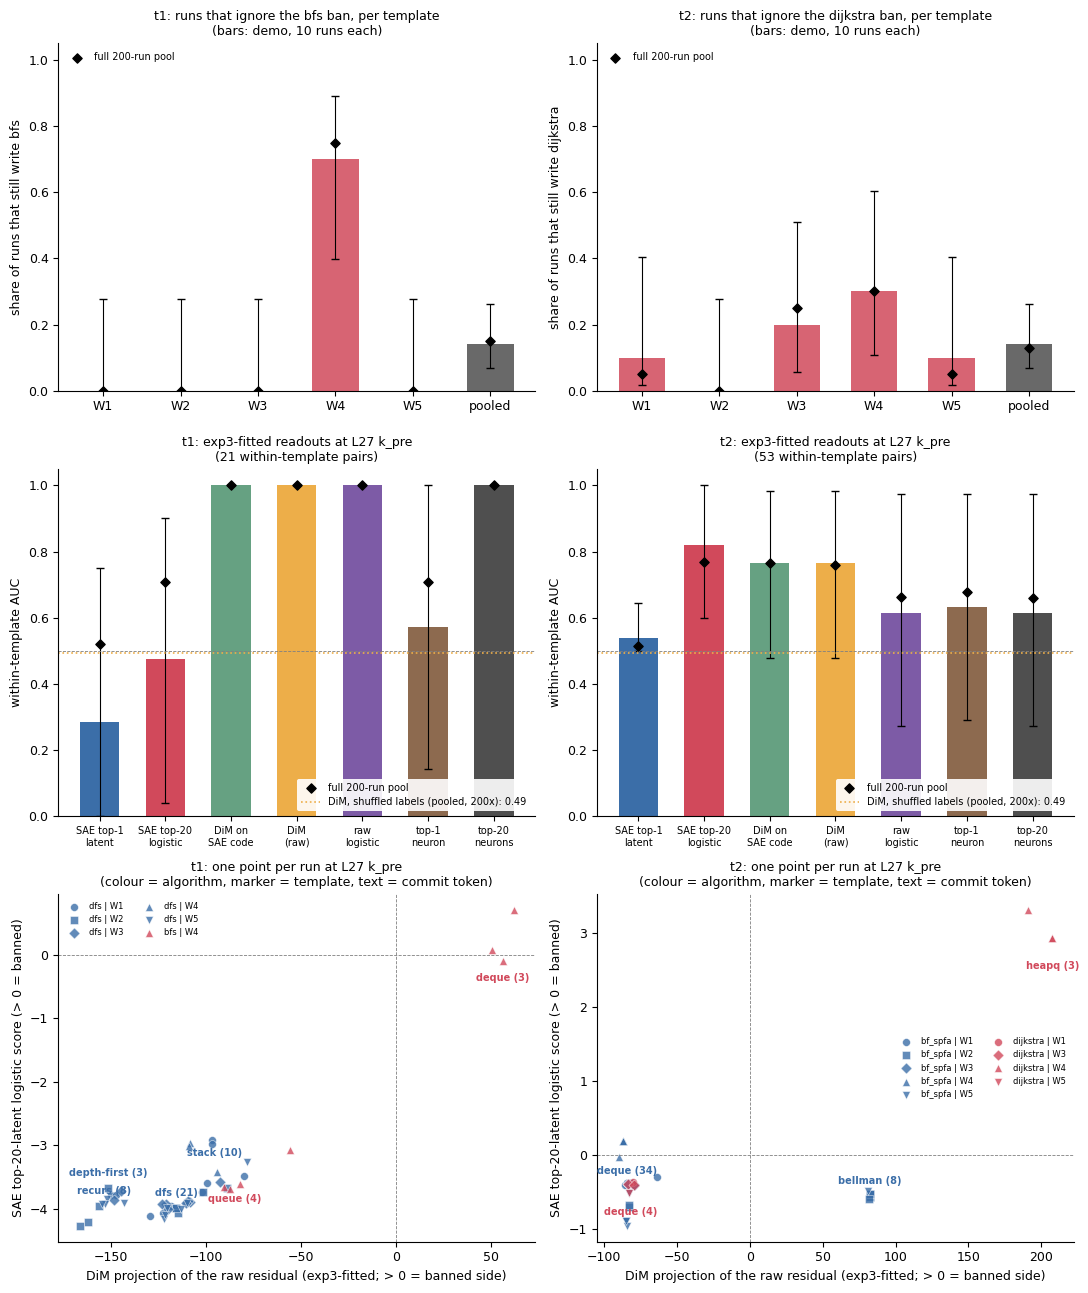

=== key numbers: demo subset (full 200-run pool in brackets) ===
t1: banned share 0.14 (0.15) | W4 alone 0.70 (0.75) | pooled event gate True (True) | landing {'dfs': 43, 'bfs': 7}
t2: banned share 0.14 (0.13) | W4 alone 0.30 (0.30) | pooled event gate True (True) | landing {'dijkstra': 7, 'bf_spfa': 42, 'other': 1}
t1|L27|k_pre: within-template AUC  DiM 1.00 (1.00) | SAE top-1 latent 0.29 (0.52) | SAE top-20 probe 0.48 (0.71) | shuffled-label DiM pooled AUC 0.49
t2|L27|k_pre: within-template AUC  DiM 0.76 (0.76) | SAE top-1 latent 0.54 (0.51) | SAE top-20 probe 0.82 (0.77) | shuffled-label DiM pooled AUC 0.49
verify_headlines (checks 1 + 5): 4 checks, 0 mismatches
SAE transfer test (full artifact): 0/3 layers pass; dCE ratio L15 3.29, L20 1.95, L27 1.59  [rule: PASS(L) := dCE_inst(L) <= 1.5 x dCE_base(L) (spliced-in CE over response tokens)]


In [15]:
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})  # as in figures.py
C = ["#3b6ea8", "#d1495b", "#66a182", "#edae49", "#7d5ba6", "#8d6a4f", "#4f4f4f"]          # figures.py palette
MORDER = ["sae_top1", "sae_top20_lr", "sae_code_dim", "raw_dim", "raw_lr", "neuron_top1", "neuron_top20_lr"]
MNAME = {"sae_top1": "SAE top-1\nlatent", "sae_top20_lr": "SAE top-20\nlogistic", "sae_code_dim": "DiM on\nSAE code",
         "raw_dim": "DiM\n(raw)", "raw_lr": "raw\nlogistic", "neuron_top1": "top-1\nneuron",
         "neuron_top20_lr": "top-20\nneurons"}


def _f2(v):
    return "n/a" if v is None or (isinstance(v, float) and not np.isfinite(v)) else f"{v:.2f}"


def _sc(r):
    return SCORES[(r["task"], r["template"], r["sample_id"])]


def _yerr(v, lo, hi):
    # error-bar lengths, clamped at 0: a Wilson bound at a share of 0 or 1 can sit ~1e-17 on the wrong side,
    # and a bootstrap percentile CI need not contain the point estimate (matplotlib rejects negative lengths)
    return [[max(v - lo, 0.0)], [max(hi - v, 0.0)]]


fig, axes = plt.subplots(3, 2, figsize=(11, 13))
for col, t in enumerate(TASKS):
    # row 1: banned share per template (Wilson 95% CI)
    ax = axes[0, col]
    ws = TEMPLATE_IDS + ["pooled"]
    for j, w in enumerate(ws):
        p = fresh["per_task"][t][w]
        v, (lo, hi) = p["banned_share"], p["banned_share_wilson"]
        ax.bar(j, v, 0.6, color=C[6] if w == "pooled" else C[1], alpha=0.85)
        ax.errorbar(j, v, yerr=_yerr(v, lo, hi), fmt="none", ecolor="k", capsize=3, lw=0.8)
    ax.scatter(range(len(ws)), [REF["fresh_pool_summary"][t][w]["banned_share"] for w in ws], marker="D", s=22,
               color="k", zorder=3, label="full 200-run pool")
    ax.set_xticks(range(len(ws)), ws)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel(f"share of runs that still write {BANNED[t]}")
    ax.set_title(f"{t}: runs that ignore the {BANNED[t]} ban, per template\n(bars: demo, {N_PER_CELL} runs each)",
                 fontsize=9)
    ax.legend(frameon=False, fontsize=7, loc="upper left")

    # row 2: within-template AUC of every exp3-fitted readout (run-bootstrap 95% CI)
    ax = axes[1, col]
    key = f"{t}|L{READOUT_LAYER}|k_pre"
    tr = rep_i["configs"].get(key, {}).get("transfer_from_exp3", {})
    ref = REF["readout_i_replication"][key]["transfer_from_exp3"]
    for j, m in enumerate(MORDER):
        r = tr.get(m, {})
        a = r.get("auc_within_template")
        if a is not None and np.isfinite(a):
            ax.bar(j, a, 0.6, color=C[j % len(C)])
            ci = r.get("within_ci_runs") or [None, None]
            if ci[0] is not None:
                ax.errorbar(j, a, yerr=_yerr(a, ci[0], ci[1]), fmt="none", ecolor="k", capsize=3, lw=0.8)
    ax.scatter(range(len(MORDER)), [ref[m]["auc_within_template"] for m in MORDER], marker="D", s=22, color="k",
               zorder=3, label="full 200-run pool")
    ax.axhline(0.5, color="grey", lw=0.6, ls="--")
    pl = VER["checks"].get(f"placebo_replication_shuffled_{key}", {}).get("placebo_mean_auc")
    if pl is not None:
        ax.axhline(pl, color=C[3], lw=1.2, ls=":", label=f"DiM, shuffled labels (pooled, {N_PLACEBO}x): {pl:.2f}")
    ax.set_xticks(range(len(MORDER)), [MNAME[m] for m in MORDER], fontsize=7)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("within-template AUC")
    n_pairs = next(iter(tr.values()), {}).get("n_within_pairs", 0)
    ax.set_title(f"{t}: exp3-fitted readouts at L{READOUT_LAYER} k_pre\n({n_pairs} within-template pairs)", fontsize=9)
    ax.legend(frameon=True, framealpha=0.9, edgecolor="none", fontsize=7, loc="lower right")

    # row 3: per-run readout geometry (L27 k_pre state projected on two exp3-fitted directions)
    ax = axes[2, col]
    for lab, colr in ((SUBSTITUTE[t], C[0]), (BANNED[t], C[1])):
        for w, mk in zip(TEMPLATE_IDS, "osD^v"):
            pts = [(_sc(r)["raw_dim"], _sc(r)["sae_top20_lr"]) for r in C1_ROWS
                   if r["task"] == t and r["label"] == lab and r["template"] == w and _sc(r)]
            if pts:
                ax.scatter(*zip(*pts), color=colr, marker=mk, s=32, alpha=0.8, edgecolor="white", lw=0.4,
                           label=f"{lab} | {w}")
    # text: the commit token (first algorithm-identifying lexicon match, i.e. the token right after k_pre) of each
    # (algorithm, token) cluster, with its run count, at the cluster median; offsets alternate so labels do not overlap
    groups = defaultdict(list)
    for r in C1_ROWS:
        if r["task"] == t and r["label"] in (BANNED[t], SUBSTITUTE[t]) and _sc(r):
            groups[(r["label"], (r["evidence_term"] or "none").lower())].append((_sc(r)["raw_dim"],
                                                                                 _sc(r)["sae_top20_lr"]))
    for k, ((lab, term), pts) in enumerate(sorted(groups.items(), key=lambda kv: np.median([p[0] for p in kv[1]]))):
        xs, ys = zip(*pts)
        dy = -(12 + 10 * (k % 2)) if lab == BANNED[t] else 7 + 10 * (k % 2)
        ax.annotate(f"{term} ({len(pts)})", (float(np.median(xs)), float(np.median(ys))), textcoords="offset points",
                    xytext=(0, dy), ha="center", fontsize=7, fontweight="bold",
                    color=C[1] if lab == BANNED[t] else C[0])
    ax.axvline(0, color="grey", lw=0.6, ls="--")
    ax.axhline(0, color="grey", lw=0.6, ls="--")
    ax.set_xlabel("DiM projection of the raw residual (exp3-fitted; > 0 = banned side)")
    ax.set_ylabel("SAE top-20-latent logistic score (> 0 = banned)")
    ax.set_title(f"{t}: one point per run at L{READOUT_LAYER} k_pre\n(colour = algorithm, marker = template, "
                 f"text = commit token)", fontsize=9)
    ax.legend(frameon=False, fontsize=6, ncol=2)
fig.tight_layout()
fig.savefig(FIGS / "demo_summary.png", dpi=150)
plt.show()

print("=== key numbers: demo subset (full 200-run pool in brackets) ===")
for t in TASKS:
    p, f = fresh["per_task"][t]["pooled"], REF["fresh_pool_summary"][t]["pooled"]
    w4, f4 = fresh["per_task"][t]["W4"], REF["fresh_pool_summary"][t]["W4"]
    print(f"{t}: banned share {_f2(p['banned_share'])} ({_f2(f['banned_share'])}) | W4 alone {_f2(w4['banned_share'])} "
          f"({_f2(f4['banned_share'])}) | pooled event gate {p['event_gate_pass']} ({f['event_gate_pass']}) | "
          f"landing {p['landing']}")
for t in TASKS:
    key = f"{t}|L{READOUT_LAYER}|k_pre"
    tr = rep_i["configs"].get(key, {}).get("transfer_from_exp3", {})
    ref = REF["readout_i_replication"][key]["transfer_from_exp3"]
    pl = VER["checks"].get(f"placebo_replication_shuffled_{key}", {}).get("placebo_mean_auc")
    print(f"{key}: within-template AUC  DiM {_f2(tr.get('raw_dim', {}).get('auc_within_template'))} "
          f"({_f2(ref['raw_dim']['auc_within_template'])}) | SAE top-1 latent "
          f"{_f2(tr.get('sae_top1', {}).get('auc_within_template'))} ({_f2(ref['sae_top1']['auc_within_template'])}) | "
          f"SAE top-20 probe {_f2(tr.get('sae_top20_lr', {}).get('auc_within_template'))} "
          f"({_f2(ref['sae_top20_lr']['auc_within_template'])}) | shuffled-label DiM pooled AUC {_f2(pl)}")
print(f"verify_headlines (checks 1 + 5): {VER['n_checks']} checks, {VER['n_mismatches']} mismatches")
_tt = REF["sae_transfer_test"]
print(f"SAE transfer test (full artifact): {_tt['n_pass']}/3 layers pass; dCE ratio "
      + ", ".join(f"L{L} {r:.2f}" for L, r in _tt["ratio_by_layer"].items()) + f"  [rule: {_tt['rule']}]")

### Reading the results

- **A ban mostly substitutes; it does not subtract, and it does not make the model inventive.** Under four of the five
  templates, T1 never produces BFS. Instead the model writes DFS, the next most common grid-path algorithm. Under
  W4, *"BFS is not allowed here."*, it still writes BFS most of the time. T2 shows the same pattern, with
  Bellman-Ford/SPFA standing in for Dijkstra. On T2 the ban fails most often under W3 and W4. Across the pool almost
  nothing lands outside the banned algorithm and its one natural substitute; the only exception is a single `other`
  run. So the *wording* of a ban decides how often it works. What replaces the banned algorithm is the runner-up, not
  a novel solution.
- **The cheap baseline wins.** The class-mean-difference (DiM) direction was fitted on exp3 states. On the fresh pool
  it separates banned from substitute runs *within the same template*:
  - **T1**: perfectly. This rests on W4's pairs alone, the only template with both classes.
  - **T2**: AUC about 0.76 in both the demo and the full pool, but with a wide CI.

  The single best SAE latent from exp3 does not transfer. The top-20-latent probe roughly ties DiM on T2, with
  overlapping CIs, but it falls to chance inside W4 on T1. Every SAE readout here is also out-of-distribution, because
  the base→instruct transfer test failed. Shuffled labels give about 0.5.
- **What `k_pre` measures: the geometry panels show it directly.** `k_pre` is the state just before the first
  algorithm-identifying token. The runs cluster by *that token* much more than by the algorithm they end up writing.
  - **T2.** Dijkstra runs that commit at `heapq` sit far out on the banned side. Dijkstra runs that commit at `deque`
    sit inside the Bellman-Ford/SPFA `deque` cluster. Bellman-Ford runs whose first match is the word `Bellman` also
    sit on the banned side. T2's AUC of about 0.76 is therefore mostly a `heapq`-versus-`deque` contrast.
  - **T1.** BFS runs that commit at `deque` are far from every DFS run. BFS runs that commit at `queue` sit next to
    the DFS `stack` runs.

  So these readouts largely read *which word comes next*, not an earlier algorithm decision. The artifact flags this
  itself: the readout is the state at the first lexicon match, not at the decision. That is why it reports all
  readouts as descriptive, not causal.
- **Demo vs full run.** The demo uses half of the pool, 10 runs per template. Its CIs are therefore wider, and a few
  per-template shares differ from the full pool. Each number sits next to its full-pool value, shown as black diamonds
  in the figure and as bracketed values in the printout.
  - `N_PER_CELL = 10` already uses the whole demo file.
  - All 200 runs, every layer and position, and the GPU stages need the original pipeline:
    `uv run method.py --stage vllm1 | label | hf | analyse | final | verify`.